In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/newl3_iascone/'
import os
#os.mkdir(figpth)

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_cells_dev/utils')
from cell_builder_utils import l2_params, _get_dends, _get_pyr_soma, Cell
from iascone_mechs_utils import Mechs, get_iascone_params, Ih_condu_apical, distribute_gbar
from plot_utils import fig_conductances, fig_compartments
from functools import partial
from hay_mechs_utils import linear_gbar
from hnn_core.viz import plot_cell_morphology

from matplotlib import colormaps
from scipy import signal
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

cmap = colormaps['viridis']
cols_dist = cmap.colors[0:len(cmap.colors):20]

In [2]:
def exp_func(t, tau, A, C):
    return A * (1 - np.exp(-t / tau)) + C

In [3]:
iascone_model_params = {'soma': {'NaTs2_t_32d': 20_400e-4*3.5,
                                'SKv3_1': 6_930e-4*4.5,
                                'Nap_Et2': 1e-4/2,
                                'Ca_HVA': 9.92e-04,
                                'Ca_LVAst': 34.3e-4,
                                
                                #'SK_E2': 0.099433/2*0.001,
                                'pas': 1.0 / 35000.0,
                                'Ih': 0.000080*0.5,
                                'Im': 8e-3},
                        'basal': {'NaTs2_t_32d': 0.008009*0.01,#partial(linear_gbar,0.008009/2,0,255),
                                  'SKv3_1': 0.000513*0.01,#partial(linear_gbar,0,6_930e-4*0.1,255),
                                  'Ih': 0.00008,
                                  'pas':  1.0 / 35000.0},
                        'dend': {'NaTa_t_32d': 0.008009*0.1,
                                'SKv3_1': 0.000513*0.1,
                                'Ca_HVA': partial(linear_gbar, 2.78e-5/2*1., 2.78e-5/2*1, 400, hotzone=[400, 600], hotzone_factor=1),
                                'Ca_LVAst': partial(linear_gbar, 93.5e-6, 93.5e-6*1, 400, hotzone=[400, 600], hotzone_factor=1),
                                'pas': 1.0 / 35000.0,
                                #'SK_E2': 0.099433/2*0.00001,
                                'Ih': {'gbar': 0.000080, 'offset': -0.869600, 'slope':2, 'factor_exp':1/110},
                                'Im': 8e-3*0},
                        'e_pas': -75}

In [4]:
# get paramaters
section_params, end_pts, cell_tree = l2_params()

# build sections
section_names = list(end_pts.keys())

v_init = {'soma': -68.85159703362191,
        'basal_1': -68.9013799898162,
        'basal_2': -69.04833422207797,
        'basal_3': -69.04833422207797,
        'apical_oblique': -68.67137672693937,
        'apical_trunk': -68.69214528583284,
        'apical_1': -67.42523827628489,
        'apical_tuft': -65.21723613840336}

sections = _get_dends(section_params, 'L2Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L2Pyr', end_pts['soma'], v_init=v_init['soma'])

mech_class = Mechs(pth_mod)

l2pyr= Cell(sections, cell_tree, cell_type = 'L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)


In [5]:
# RMP

l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l2pyr.build()

l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)
distance = []
h.distance(sec = l2pyr._nrn_sections['soma'])
section_names = ['soma', 'basal_1','basal_2', 'basal_3', 'apical_oblique', 'apical_trunk','apical_1', 'apical_tuft']
sec_seg = []

v_s = []
for s, section in enumerate(section_names):
    v_s.append(h.Vector().record(l2pyr._nrn_sections[section](0.5)._ref_v))

t = h.Vector().record(h._ref_t)
h.celsius = 37
h.finitialize()
h.continuerun(100 * ms)
h.dt = 0.025
for s, section in enumerate(section_names):
    v = v_s[s].as_numpy()
    print(f"'{section}': {v[-1]},")

'soma': -67.50343532695135,
'basal_1': -67.53379991750174,
'basal_2': -67.62375877095587,
'basal_3': -67.62375877095587,
'apical_oblique': -67.24594970054235,
'apical_trunk': -67.33161899391531,
'apical_1': -66.09200493536679,
'apical_tuft': -64.07305992013058,


In [6]:
h.dt

0.025

In [7]:
def fig_voltage(model, clamp_current, l_stim=100):
    
    section_names = ['apical_tuft', 'apical_1', 'apical_trunk', 'basal_1', 'basal_2', 'basal_3', 'apical_oblique', 'soma']

    voltg = [None]*len(section_names)
    for i, section in enumerate(section_names):
        voltg[i] = h.Vector().record(model._nrn_sections[section](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    fig, ax = plt.subplots(2,1, figsize=(4,8), height_ratios=[0.25, 1], sharex=True)

    for c in clamp_current:
        ax[0].plot(t,c, color='k')

    yticks_v = []
    yticklabels_v = []

    cv = 0
    for i,section in enumerate(section_names):
        
        ax[1].plot(t,voltg[i] + cv)

        yticks_v.append(-75+cv)
        yticks_v.append(50+cv)

        yticklabels_v.append(str(np.round(-75)))
        yticklabels_v.append(str(np.round(50)))

        cv -= 200

    ax[1].set_yticks(yticks_v)
    ax[1].set_yticklabels(yticklabels_v)
    ax[1].set_ylabel('voltage $\mu V$')
    ax[1].set_xlabel('time (ms)')
    ax[1].legend(section_names)

    return fig

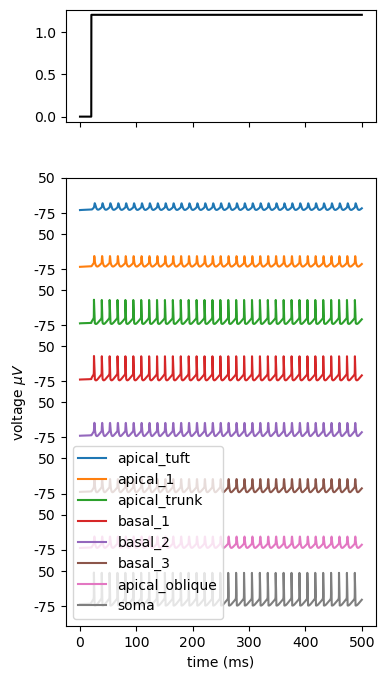

In [8]:
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

num_pulse = 1
stim = [None]*num_pulse
clamp_current = [None]*num_pulse
for i in range(num_pulse):
    stim[i] = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 20+(10*i)
    stim[i].dur = 1000
    stim[i].amp = 1.2
    clamp_current[i] = h.Vector().record(stim[i]._ref_i)

fig = fig_voltage(l2pyr, clamp_current, l_stim=500)
fig.savefig(figpth+'continuous_clamp.png')

In [9]:
# input resistance
section_names = ['apical_tuft', 'apical_1', 'apical_trunk', 'basal_1', 'basal_2', 'basal_3', 'apical_oblique', 'soma']
inp_res_apcl = []
inp_res_basal = []
inp_res_soma = []
inp_res_oblq = []

distance_apcl = []
distance_basal = []
distance_oblq = []
soma = []

del l2pyr 
h('forall delete_section()')

l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

h.distance(sec = l2pyr._nrn_sections['soma'])
for s, section in enumerate(section_names):
    for i, seg in enumerate(l2pyr._nrn_sections[section]):
        
        impedance = h.Impedance()
        h.celsius = 37
        h.finitialize()
        impedance.loc(seg.x, sec=l2pyr._nrn_sections[section])
        impedance.compute(0)

        if 'basal' in section:
            inp_res_basal.append(impedance.input(l2pyr._nrn_sections[section](seg.x)))
            distance_basal.append(h.distance(seg))
        elif section == 'apical_oblique':
            inp_res_oblq.append(impedance.input(l2pyr._nrn_sections[section](seg.x)))
            distance_oblq.append(h.distance(seg))
        elif 'apical' in section:
            inp_res_apcl.append(impedance.input(l2pyr._nrn_sections[section](seg.x)))
            distance_apcl.append(h.distance(seg))

        elif section == 'soma':
            inp_res_soma.append(impedance.input(l2pyr._nrn_sections[section](seg.x)))


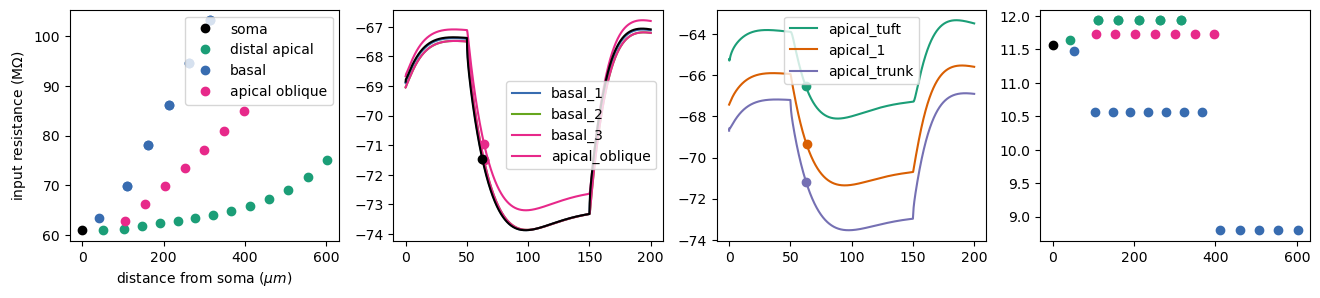

In [10]:
cols_apcl = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cols_basal = np.array(([56,108,176], [102,166,30], [231,41,138], [231,41,138]))/255

fig, ax = plt.subplots(1,4, figsize=(16, 3))

ax[0].plot(0, inp_res_soma, 'o', color='k', label='soma')
ax[0].plot(distance_apcl, inp_res_apcl, 'o', color=cols_apcl[0], label='distal apical')
ax[0].plot(distance_basal, inp_res_basal, 'o', color=cols_basal[0], label='basal')
ax[0].plot(distance_oblq, inp_res_oblq, 'o', color=cols_basal[2], label='apical oblique')
ax[0].set_xlabel('distance from soma ($\mu m$)')
ax[0].set_ylabel('input resistance (M$\Omega$)')

section_names = ['apical_tuft', 'apical_1', 'apical_trunk', 'basal_1', 'basal_2', 'basal_3', 'apical_oblique', 'soma']

voltg = [None]*len(section_names)
tau_m_apcl_mnl = []
tau_m_basal_mnl = []
tau_m_soma_mnl = []
tau_m_oblq_mnl = []

tau_m_apcl_cf = []
tau_m_basal_cf = []
tau_m_soma_cf = []
tau_m_oblq_cf = []

# Goal: tau_m = 17 ms
cb = 0
ca = 0
for s, section in enumerate(section_names):
    for i, seg in enumerate(l2pyr._nrn_sections[section]):

        l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
        l2pyr.build()
        l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)
        h.distance(sec = l2pyr._nrn_sections['soma'])

        stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
        stim.delay = 50
        stim.dur = 100
        stim.amp = -0.15

        voltg[i] = h.Vector().record(l2pyr._nrn_sections[section](0.5)._ref_v)

        t = h.Vector().record(h._ref_t)

        h.celsius = 37
        h.finitialize()
        h.continuerun(200 * ms)

        v_np = voltg[i].as_numpy()
        t_np = t.as_numpy()
        start_idx = np.where(t_np > stim.delay)[0][0]

        # maximum amplitude
        max_ampl = v_np[start_idx]  - np.min(v_np)
        frac_ampl = v_np[start_idx]  - max_ampl * 0.63                 # 63% of amplitude
        thresh_tp = np.argmin(np.abs(v_np[:np.argmin(v_np)] - frac_ampl))       # time point when threshold is reached

        

        start_idx = np.where(t_np > stim.delay)[0][0]
        end_idx = np.where(t_np > stim.delay + stim.dur*0.9)[0][0]      # steady state, see https://pmc.ncbi.nlm.nih.gov/articles/PMC2775376/

        t_rise = t_np[start_idx:end_idx] - stim.delay # Time starting at 0
        v_rise = v_np[start_idx:end_idx]

        delta_v = np.mean(v_rise) - np.mean(v[:start_idx])
        # Fit the exponential function to the data
        popt, pcov = curve_fit(exp_func, t_rise, v_rise, p0=[10, abs(delta_v), v_rise[0]])
        tau_m_fitted = popt[0] # This is the fitted time constant in ms

        
        if section == 'soma':
            tau_m_soma_mnl.append(t_np[thresh_tp] - t_np[start_idx])  # time constant
            tau_m_soma_cf.append(tau_m_fitted)
        elif 'basal' in section:
            tau_m_basal_mnl.append(t_np[thresh_tp] - t_np[start_idx])
            tau_m_basal_cf.append(tau_m_fitted)
        elif section == 'apical_oblique':
            tau_m_oblq_mnl.append(t_np[thresh_tp] - t_np[start_idx])
            tau_m_oblq_cf.append(tau_m_fitted)
        elif 'apical' in section:
            tau_m_apcl_mnl.append(t_np[thresh_tp] - t_np[start_idx])
            tau_m_apcl_cf.append(tau_m_fitted)

    if section == 'soma':
        ax[1].plot(t, voltg[i], color='k')
        ax[1].plot(t_np[thresh_tp], v_np[thresh_tp], 'o', color='k')
    elif section == 'apical_oblique' or 'basal' in section:
        ax[1].plot(t, voltg[i], color=cols_basal[cb], label=section)
        ax[1].plot(t_np[thresh_tp], v_np[thresh_tp], 'o', color=cols_basal[cb])
        cb+=1
    else:
        ax[2].plot(t, voltg[i], color=cols_apcl[ca], label=section)
        ax[2].plot(t_np[thresh_tp], v_np[thresh_tp], 'o', color=cols_apcl[ca])
        ca+=1

ax[3].plot(0, tau_m_soma_cf, 'o', color='k')
ax[3].plot(distance_basal, tau_m_basal_cf, 'o', color=cols_apcl[0])
ax[3].plot(distance_apcl, tau_m_apcl_cf, 'o', color=cols_basal[0])
ax[3].plot(distance_oblq, tau_m_oblq_cf, 'o', color=cols_basal[2])

ax[1].legend()
ax[2].legend()
ax[0].legend()

In [11]:
def attenuation_from_section(ref_sect, amp, stim_dur, ax):


    amp_ref = []
    amp_dend = []

    distance = []
    i = 0

    l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)
    h.distance(sec = l2pyr._nrn_sections[ref_sect])
    
    
    stim = h.IClamp(l2pyr._nrn_sections[ref_sect](0.5))
    stim.delay = 20
    stim.dur = stim_dur
    stim.amp = amp

    t = h.Vector().record(h._ref_t)
    
    ref_voltg = h.Vector().record(l2pyr._nrn_sections[ref_sect](0.5)._ref_v)
    
    sections_minus_ref = [section for section in section_names if section != ref_sect]

    upstroke = []
    for s, section in enumerate(sections_minus_ref):
        for sg, seg in enumerate(l2pyr._nrn_sections[section]):
            
            dend_voltg = h.Vector().record(l2pyr._nrn_sections[section](seg.x)._ref_v)
        
            distance.append(h.distance(seg))
            
            h.celsius = 37
            h.finitialize()
            h.continuerun(250 * ms)
            
            # low-pass filter 5KHz like in Gidon et al.,
            sfreq = 1000/np.diff(t.as_numpy())[0]
            b, a = signal.butter(0, 5000, btype='low', analog=False, fs=sfreq)

            v = dend_voltg.as_numpy()
            d_filt = signal.lfilter(b, a, v)
            r_filt = signal.lfilter(b, a, ref_voltg.as_numpy())

            if amp > 0:  
                t_np = t.as_numpy()

                # upstroke per ms (Gidon et al., 2020 Fig S5 A)
                upstroke.append(np.max(np.diff(d_filt))/np.diff(t_np)[0])     

            amp_ref.append(np.max(r_filt) - np.min(r_filt))
            amp_dend.append(np.max(d_filt) - np.min(d_filt))

            ax.plot(t, ref_voltg, color='k')
            ax.plot(t, dend_voltg, color=cols_dist[i])
            i += 1

    cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)
    ax.set_ylabel('membrane potential (mV)')
    ax.set_xlabel('time (ms)')
    # calculate attenuation
    atten = np.array(amp_dend) / np.array(amp_ref) * 100

    fig.savefig(os.path.join(figpth, f'attenuation_from_{ref_sect}_amp_{amp}.png'))
    fig.savefig(os.path.join(figpth, f'attenuation_from_{ref_sect}_amp_{amp}.svg'))

    return atten, distance, upstroke

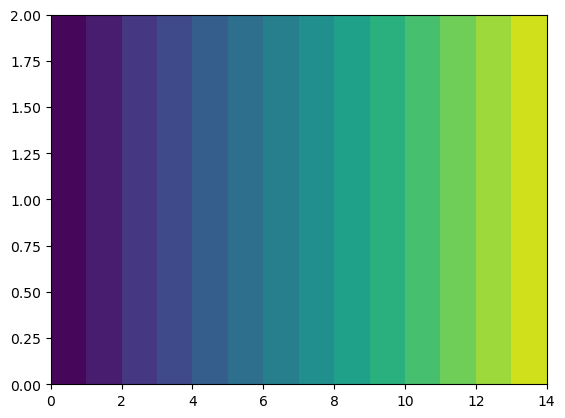

In [12]:
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
del l2pyr
h('forall delete_section()')

l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)


distance = []
h.distance(sec = l2pyr._nrn_sections['soma'])
for section in section_names:
    for seg in l2pyr._nrn_sections[section]:
        distance.append(h.distance(seg.x, sec=seg.sec))

im = plt.pcolormesh(np.tile(np.array(distance),(2,1)), cmap='viridis', vmin=0, vmax=650)


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_41666/244574546.py:60: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 1600x300 with 6 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_41666/244574546.py:60: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 1600x300 with 7 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)


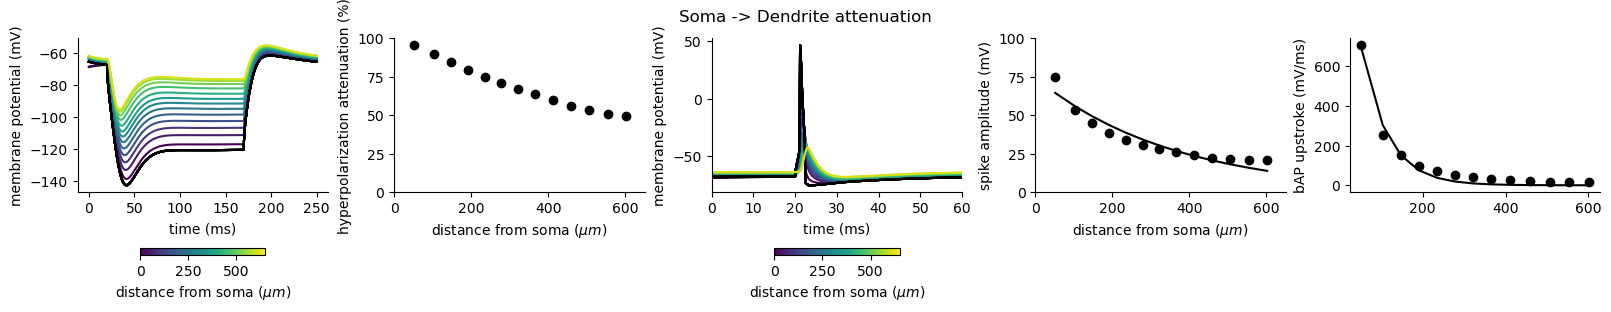

In [13]:
def exp_decay(x, lambda_val, A):
    return A * np.exp(-x / lambda_val)


fig, ax = plt.subplots(1,5, figsize=(16,3), constrained_layout=True)

# soma to dendrite attenuation
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
ref_sect = 'soma'

# hyperpolarization attenuation
hyperpol_atten, elec_sep, _ = attenuation_from_section(ref_sect, amp=-2, stim_dur=150, ax=ax[0])

# ax[0].set_ylim([-150, -40])
# ax[0].set_yticks([-150, -100, -50])
ax[1].plot(elec_sep, hyperpol_atten, 'o', color='k')
ax[1].set_xlabel('distance from soma ($\mu m$)')
ax[1].set_ylabel('hyperpolarization attenuation (%)')
#ax[1].set_ylim([0, 100])
ax[1].set_yticks(np.arange(0, 101, 25))

ax[1].set_xlim([0, 650])

# spike attenuation
spike_amp, _, upstroke = attenuation_from_section(ref_sect, amp=3, stim_dur=3,ax=ax[2])

ax[3].plot(elec_sep, spike_amp, 'o', color='k')
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(spike_amp), p0=[100, spike_amp[0] ])
lambda_spike_amp = popt[0]
ax[3].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')

ax[3].set_xlabel('distance from soma ($\mu m$)')
ax[3].set_ylabel('spike amplitude (mV)')
#ax[3].set_ylim([0, 100])
ax[3].set_xlim([0, 650])

# ax[2].set_ylim([-70, 40])
# ax[2].set_yticks([-70, 0, 40])
ax[2].set_xlim([0, 60])
ax[3].set_yticks(np.arange(0, 101, 25))


ax[4].plot(elec_sep, upstroke, 'o', color='k')
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(upstroke), p0=[100, upstroke[0] ])
ax[4].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')
lambda_upstroke = popt[0]
#ax[4].set_ylim([0, 250])
ax[4].set_ylabel('bAP upstroke (mV/ms)')

fig.suptitle('Soma -> Dendrite attenuation')

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

fig.savefig(os.path.join(figpth, 'summary_attenuation_soma_dend.png'), dpi=300)
fig.savefig(os.path.join(figpth, 'summary_attenuation_soma_dend.pdf'), dpi=300)

In [14]:
lambda_upstroke, lambda_spike_amp

(np.float64(62.83662685217335), np.float64(358.4497340847442))

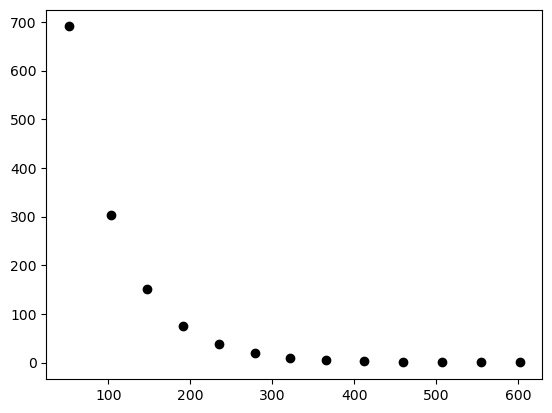

In [15]:
plt.plot(elec_sep, exp_decay(np.array(elec_sep), *popt), 'o', color='k')

Text(0.5, 1.0, 'calcium concentration (mM)')

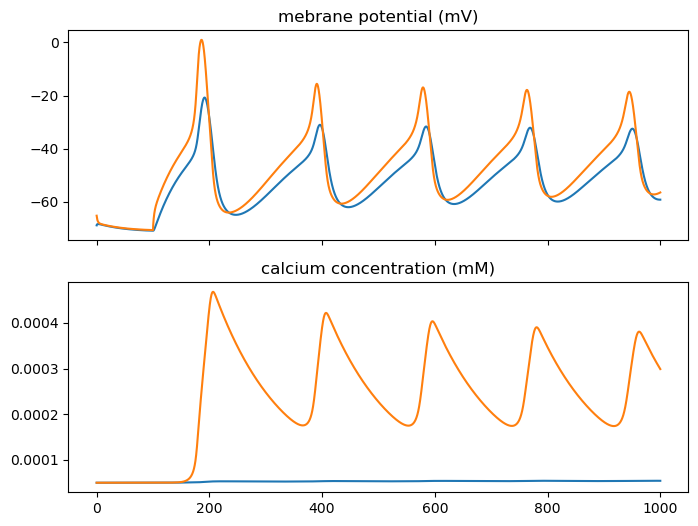

In [16]:
# calcium spikes?

iascone_model_params = {'soma': {'NaTs2_t_32d': 0.926705*0,
                                'SKv3_1': 0.102517*0,
                                'Ca_HVA': 0.000374*0.01,
                                'Ca_LVAst': 34.3e-4,
                                
                                #'SK_E2': 0.099433/2,
                                'pas': 1.0 / 37000.0,
                                'Ih': 0.000080,
                                'Im': 8e-3*0.1},
                        'basal': {'NaTs2_t_32d': 0.008009*0.01,#partial(linear_gbar,0.008009/2,0,255),
                                  'SKv3_1': 0.000513*0.01,#partial(linear_gbar,0,6_930e-4*0.1,255),
                                  'Ih': 0.00008,
                                  'pas':  1.0 / 37000.0},
                        'dend': {'NaTa_t_32d': 0.008009*0.01,
                                'SKv3_1': 0.000513*0.1,
                                'Ca_HVA': partial(linear_gbar, 2.78e-5/2,2.78e-5/2*6.5, 400, hotzone=[500, 600], hotzone_factor=10),
                                'Ca_LVAst': partial(linear_gbar, 93.5e-6, 93.5e-6/2*4.25, 400, hotzone=[500, 600], hotzone_factor=10),
                                'pas': 1.0 / 37000.0,
                                'SK_E2': 0.099433*0.05,
                                'Ih': {'gbar': 0.000080, 'offset': -0.869600, 'slope':2, 'factor_exp':1/323},
                                'Im': 8e-3/2*0.},
                        'e_pas': -75}

del l2pyr
h('forall delete_section()')
l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)


stim = h.IClamp(l2pyr._nrn_sections['apical_tuft'](0.5))
stim.delay = 100
stim.dur = 1000
stim.amp = .25

t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)
        
dend_voltg = h.Vector().record(l2pyr._nrn_sections['apical_tuft'](0.5)._ref_v)

soma_ca = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_cai)
        
dend_ca = h.Vector().record(l2pyr._nrn_sections['apical_tuft'](0.5)._ref_cai)

h.celsius = 37
h.finitialize()
h.continuerun(1000 * ms)

fig, ax = plt.subplots(2,1, figsize=(8,6), sharex=True)
ax[0].plot(t, soma_voltg)
ax[0].plot(t, dend_voltg)
ax[0].set_title('mebrane potential (mV)')
#ax[0].set_xlim([100, 400])
ax[1].plot(t, soma_ca)
ax[1].plot(t, dend_ca)
ax[1].set_title('calcium concentration (mM)')





In [17]:
pks, properties = find_peaks(dend_voltg.as_numpy(), height=-40, prominence=5, width=5)
properties

prop_ca_spikes = {}
prop_ca_spikes['num_spikes'] = len(pks)
prop_ca_spikes['peak_heights'] = (min(properties['peak_heights']), max(properties['peak_heights']))
prop_ca_spikes['prominences'] = (min(properties['prominences']), max(properties['prominences']))
prop_ca_spikes['widths'] = (min(properties['widths']), max(properties['widths']))

import pickle
with open(os.path.join(figpth, 'l23_ca_spike.pkl'), 'wb') as f:
    pickle.dump(prop_ca_spikes, f)

lowest ampl to induce spike: 0.9000000000000004


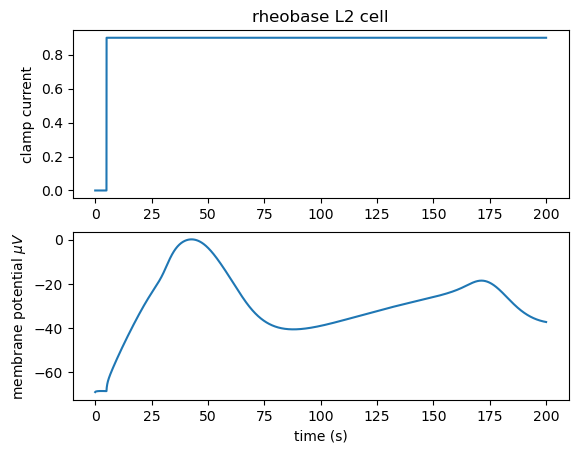

In [18]:
# rheobase
from scipy.signal import find_peaks

ampl = np.arange(0.5,1.5,0.05)

for a in ampl:
    l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

    # critical freq
    num_pulse = 3
    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 1000
    stim.amp = a
    clamp_current = h.Vector().record(stim._ref_i)

    v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)


    h.celsius = 37
    h.finitialize()
    h.continuerun(200 * ms)

    pk = find_peaks(v, height=0)
    if np.any(pk[0]) == True:
        print(f'lowest ampl to induce spike: {a}')
        break

rheo_peak = np.max(v.as_numpy())
fig, ax = plt.subplots(2,1)

ax[0].plot(t,clamp_current)
ax[0].set_ylabel('clamp current')
ax[1].plot(t,v)
ax[1].set_xlabel('time (s)')
ax[1].set_ylabel('membrane potential $\mu V$')
ax[0].set_title('rheobase L2 cell')


l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)


fig.savefig(figpth+'rheobase.png')


# add basal dendrites

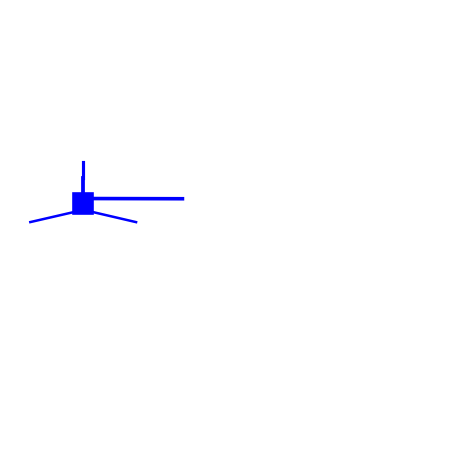

In [19]:
ax = plt.figure().add_subplot(projection='3d')
plot_cell_morphology(l2pyr, ax=ax, show=False)
ax.view_init(0,80)


HNN cell_default: proximal drive is basal_2, basal_3 and apical_oblique https://github.com/jonescompneurolab/hnn-core/blob/master/hnn_core/cells_default.py#L115

In [20]:
def epsp_sim(sections, cell_tree, epsp_strength = 1):

    # check EPSP effect
    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

    syn_inp = h.epsp(l2pyr._nrn_sections['basal_2'](0.9))
    syn_inp.onset = 5
    syn_inp.imax = epsp_strength

    h.distance(sec = l2pyr._nrn_sections['soma'])
    segments = [seg.x for seg in l2pyr._nrn_sections['basal_2']]

    voltg_basal = [None]*len(segments)
    for i, seg in enumerate(l2pyr._nrn_sections['basal_2']):
        voltg_basal[i] = h.Vector().record(seg._ref_v)

    voltg_apical = [None]*len(section_names)
    for i, section in enumerate(section_names):
        voltg_apical[i] = h.Vector().record(l2pyr._nrn_sections[section](0.5)._ref_v)
    #voltg_soma = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)
    t = h.Vector().record(h._ref_t)

    l_stim = 100
    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    return segments, voltg_basal, voltg_apical, t

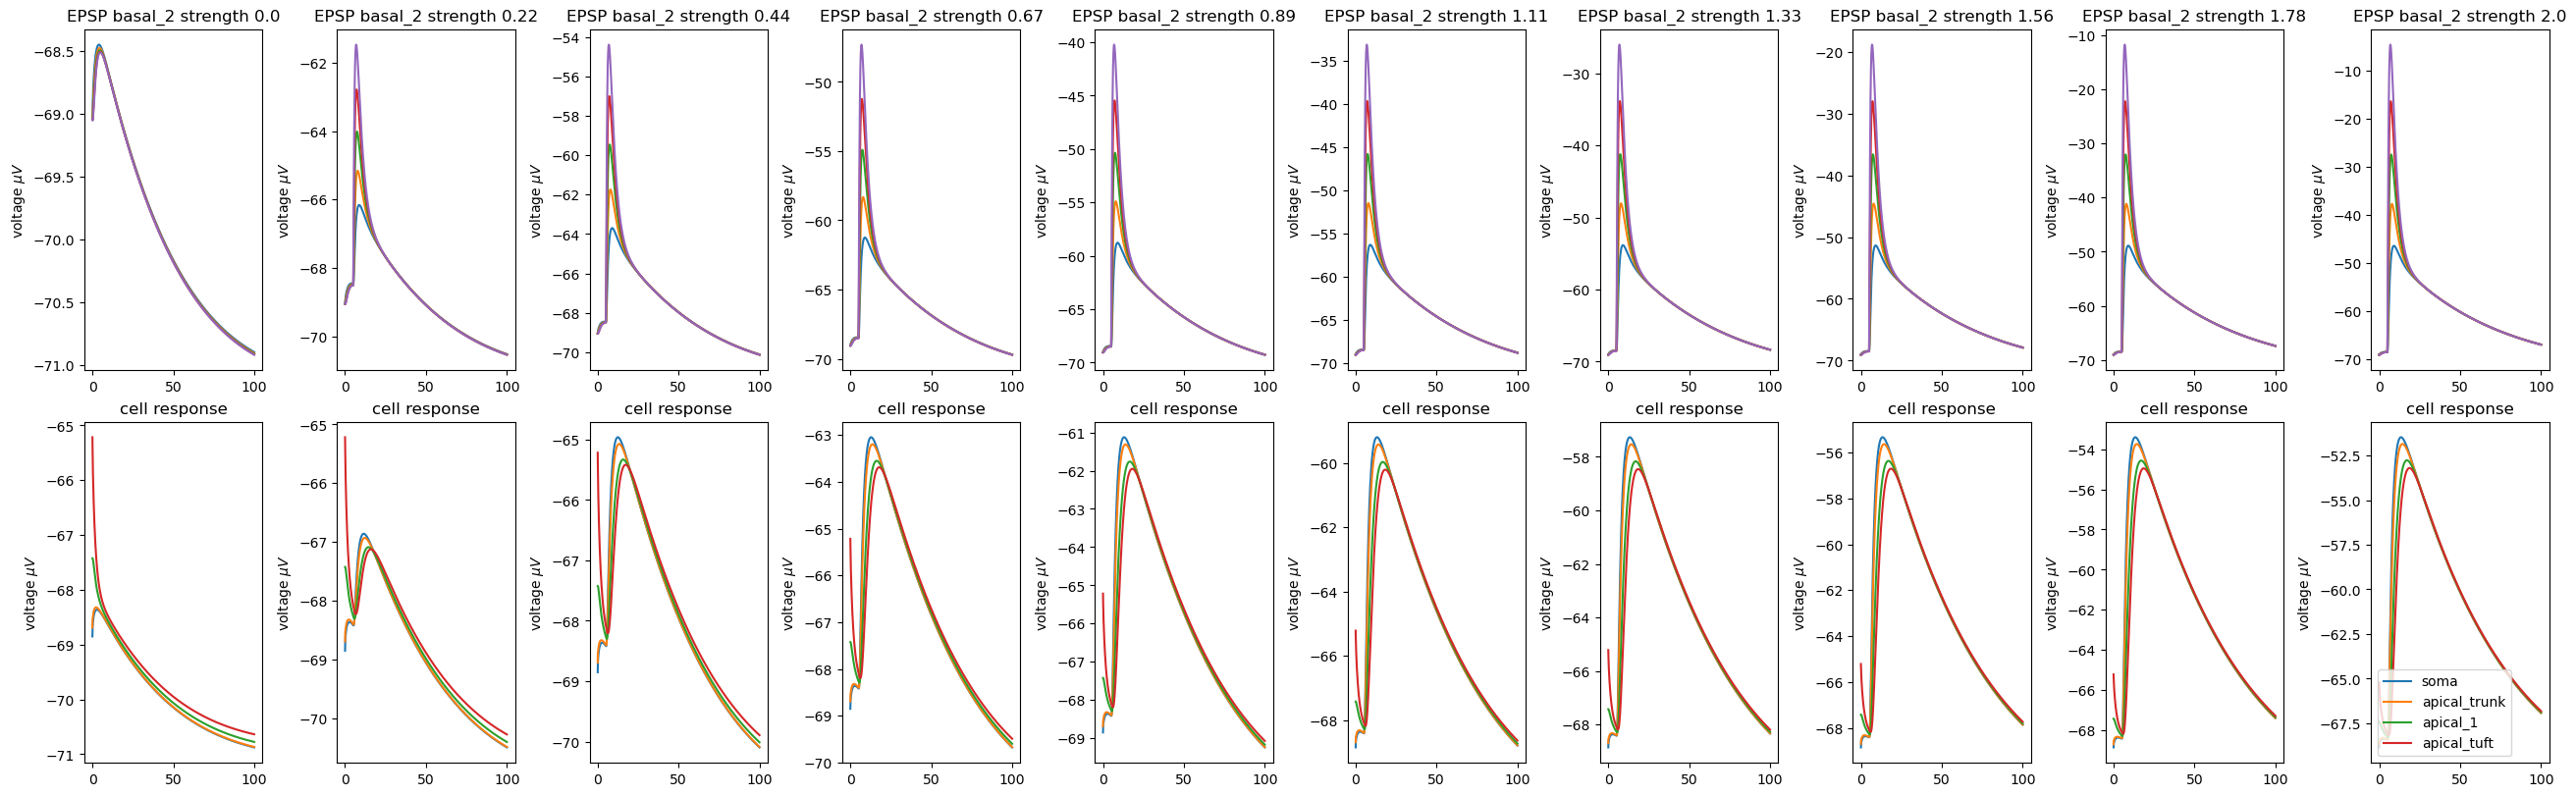

In [21]:
fig, ax = plt.subplots(2,10,figsize=(26,8), constrained_layout=True)


for a, epsp_strength in enumerate(np.linspace(0,2,10)):
    segments, voltg_basal, voltg_apical, t = epsp_sim(sections, cell_tree, epsp_strength)

    for i,v in enumerate(voltg_basal):
        ax[0, a].plot(t,v, label=str(segments[i]))

    ax[0, a].set_title(f'EPSP basal_2 strength {str(np.round(epsp_strength,2))}')
    ax[0, a].set_ylabel('voltage $\mu V$')

    for i,v in enumerate(voltg_apical):
        ax[1, a].plot(t,v, label=section_names[i])
    #ax[1, a].plot(t,voltg_soma, label=section_names[i])
    ax[1, a].set_title('cell response')
    ax[1, a].set_ylabel('voltage $\mu V$')

ax[1,-1].legend()

fig.savefig(figpth+'basal_dendrites_epsps.png')

# F-I plots??


find objectives in /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/kalmbach_l5_human_electrophysio.xls